# 01 — Banked-corner physics: why NASCAR ovals are a different problem

On a banked oval, gravity is no longer only a *load* — part of it becomes a *lateral* force that helps hold the car on the track. Banking also turns centripetal acceleration into **additional normal load**. This notebook works through the steady-state equations and shows what they mean for corner speed, tyre loads and load transfer.

**Frames:** $n$ = normal to the track surface, $y'$ = in-plane lateral (towards the infield), banking angle $\theta$, path radius $R$, speed $v$.

$$N = m\left(g\cos\theta + \frac{v^2}{R}\sin\theta\right) + \tfrac12\rho\,C_LA\,v^2 \qquad\qquad F_{y'} = m\left(\frac{v^2}{R}\cos\theta - g\sin\theta\right)$$

Grip limit: $|F_{y'}| \le \mu(N)\,N$. With constant $\mu$ and no aero, this gives the classic closed form

$$v_{max}^2 = gR\,\frac{\sin\theta + \mu\cos\theta}{\cos\theta - \mu\sin\theta}, \qquad v_{0}^2 = gR\tan\theta \;\;(\text{"hands-off" speed, } F_{y'}=0)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
RHO, G, MPH = 1.18, 9.81, 2.23694

def vmax_closed(R, th, mu):
    den = np.cos(th) - mu*np.sin(th)
    return np.where(den > 0, np.sqrt(np.clip(G*R*(np.sin(th)+mu*np.cos(th))/np.where(den>0,den,1), 0, None)), np.inf)

def vmax_numeric(R, th, mu0, m=1600., ClA=0.0, ls=0.0, Fz0=4000.):
    # bisection incl. aero downforce and tyre load sensitivity mu = mu0*(Fz/Fz0)^-ls
    lo, hi = 1., 150.
    for _ in range(60):
        v = 0.5*(lo+hi)
        N  = m*(G*np.cos(th) + v**2/R*np.sin(th)) + 0.5*RHO*ClA*v**2
        Fy = m*(v**2/R*np.cos(th) - G*np.sin(th))
        mu = mu0*(N/4/Fz0)**(-ls)
        lo, hi = (v, hi) if abs(Fy) <= mu*N else (lo, v)
    return lo

## 1. Corner speed vs. banking angle
A 215 m radius (roughly a 1.5-mile intermediate) with $\mu = 1.0$. We compare: no aero, Next Gen-like downforce, and downforce with tyre load sensitivity. The values are illustrative, not homologated data.

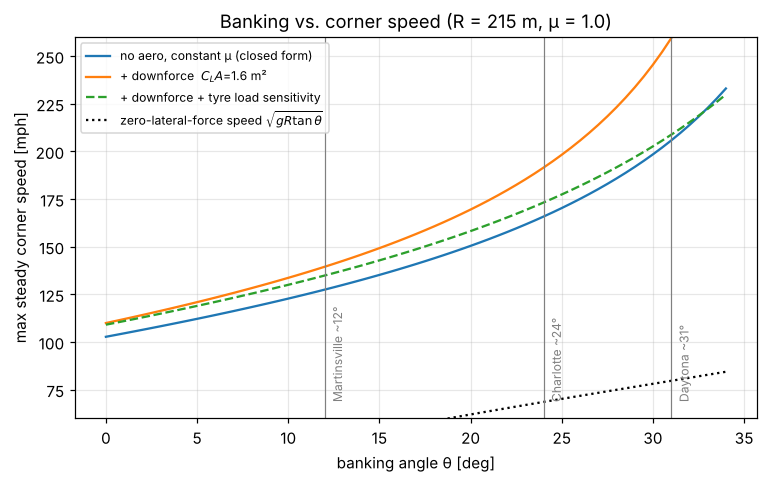

θ= 0°: no-aero  102.7 mph | aero  109.9 | aero+LS  109.1
θ=12°: no-aero  127.5 mph | aero  139.5 | aero+LS  134.9
θ=24°: no-aero  165.8 mph | aero  191.5 | aero+LS  173.2
θ=31°: no-aero  205.7 mph | aero  259.4 | aero+LS  208.7


In [2]:
R, mu = 215.0, 1.0
th_deg = np.linspace(0, 34, 69); th = np.deg2rad(th_deg)
v_closed = vmax_closed(R, th, mu)
v_aero   = np.array([vmax_numeric(R, t, mu, ClA=1.6) for t in th])
v_aerols = np.array([vmax_numeric(R, t, mu, ClA=1.6, ls=0.12) for t in th])
v_zero   = np.sqrt(G*R*np.tan(th))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(th_deg, v_closed*MPH, label='no aero, constant μ (closed form)')
ax.plot(th_deg, v_aero*MPH, label='+ downforce  $C_LA$=1.6 m²')
ax.plot(th_deg, v_aerols*MPH, '--', label='+ downforce + tyre load sensitivity')
ax.plot(th_deg, v_zero*MPH, ':', c='k', label='zero-lateral-force speed $\\sqrt{gR\\tan\\theta}$')
for name, b in [('Martinsville ~12°', 12), ('Charlotte ~24°', 24), ('Daytona ~31°', 31)]:
    ax.axvline(b, c='grey', lw=0.8); ax.text(b+0.3, 70, name, rotation=90, fontsize=8, color='grey')
ax.set(xlabel='banking angle θ [deg]', ylabel='max steady corner speed [mph]', ylim=(60, 260),
       title=f'Banking vs. corner speed (R = {R:.0f} m, μ = {mu})'); ax.legend(fontsize=8)
plt.show()

for b in [0, 12, 24, 31]:
    i = np.argmin(abs(th_deg-b))
    print(f'θ={b:2d}°: no-aero {v_closed[i]*MPH:6.1f} mph | aero {v_aero[i]*MPH:6.1f} | aero+LS {v_aerols[i]*MPH:6.1f}')

**Takeaways**
* Going from 0° to 24° banking is worth about **+40 % corner speed** at this radius. No legal aero change comes close to that.
* Load sensitivity cuts part of the gain, because banking raises $N$ and the tyres become less efficient. On a high-banked track, tyre construction and load sensitivity are first-order effects, which is why Goodyear builds track-specific tyres.
* The "hands-off" speed at Daytona-type banking is already ~140 mph+. Pack racing at ~190 mph only asks the tyres for a *moderate* lateral force, so the cars run flat out and the problem becomes **drag-limited**.

## 2. Normal load and the load-transfer ratio
The quantity that drives lateral load transfer is $a_{y'}\,h/t$. What matters for tyre balance is the transfer **relative to the normal load**, i.e. the ratio $a_{y'}/a_n$. Banking increases $a_n$ and reduces $a_{y'}$ at the same speed, so the car "sees" less roll moment per unit of tyre load.

Font 'default' does not have a glyph for '\u221d' [U+221d], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u221d' [U+221d], substituting with a dummy symbol.


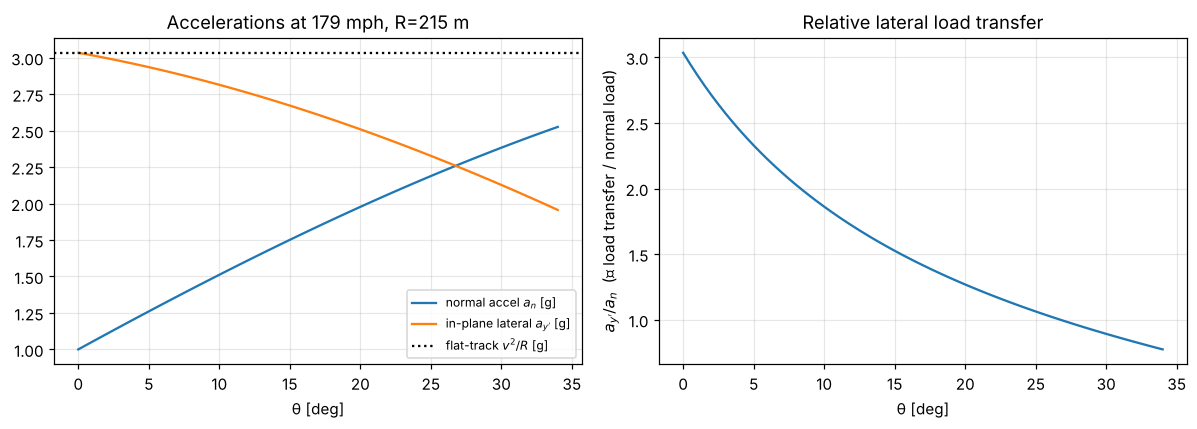

At 24°: a_n = 2.15 g, a_y' = 2.37 g  (flat track would need 3.03 g lateral)


In [3]:
v = 80.0  # m/s ~ 179 mph
a_lat_flat = v**2/R
an  = G*np.cos(th) + v**2/R*np.sin(th)
ayp = v**2/R*np.cos(th) - G*np.sin(th)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(th_deg, an/G, label='normal accel $a_n$ [g]')
ax[0].plot(th_deg, ayp/G, label="in-plane lateral $a_{y'}$ [g]")
ax[0].axhline(a_lat_flat/G, ls=':', c='k', label='flat-track $v^2/R$ [g]')
ax[0].set(xlabel='θ [deg]', title=f'Accelerations at {v*MPH:.0f} mph, R={R:.0f} m'); ax[0].legend(fontsize=8)
ax[1].plot(th_deg, ayp/an)
ax[1].set(xlabel='θ [deg]', ylabel="$a_{y'}/a_n$  (∝ load transfer / normal load)",
          title='Relative lateral load transfer')
plt.tight_layout(); plt.show()
print(f'At 24°: a_n = {np.interp(24, th_deg, an)/G:.2f} g, a_y\' = {np.interp(24, th_deg, ayp)/G:.2f} g  '
      f'(flat track would need {a_lat_flat/G:.2f} g lateral)')

**Engineering consequences**
* Springs and bump stops carry **2–3 g of vertical load** through long corners. Ride height and *platform* control under this compression set the aero map (splitter height, diffuser rake). This is why bump-stop and travel-limiter tuning matters so much.
* On high banks the lateral transfer per unit load is smaller, so **static asymmetry** (left-side weight, cross weight, asymmetric camber/pressures) dominates the balance tools. See notebook 03.
* Banking angles often **vary across the track width** (progressive banking: Homestead, Bristol, Kansas…). The racing line choice is therefore a trade-off between radius and banking, and a lap-time model needs a 3D track description, not a 2D centreline.

## 3. Radius-vs-banking: why lines move up the track
Many modern ovals have *progressive* banking: the outer lane is steeper. Is a wider, higher lane faster? Below, the inner lane has R = 215 m and θ = 20°. Each outer lane adds 4 m of radius and 1°–2° of banking per lane.

In [4]:
lanes = np.arange(0, 5)
for dth in [0.0, 1.0, 2.0]:
    vs = [vmax_numeric(215+4*k, np.deg2rad(20+dth*k), 1.0, ClA=1.6, ls=0.12) for k in lanes]
    # time through a 180° turn on that lane
    ts = [np.pi*(215+4*k)/v for k, v in zip(lanes, vs)]
    print(f'+{dth:.0f}°/lane: speeds [mph] ' + ' '.join(f'{v*MPH:6.1f}' for v in vs) +
          ' | half-lap turn time [s] ' + ' '.join(f'{t:5.2f}' for t in ts))

+0°/lane: speeds [mph]  158.2  159.9  161.7  163.4  165.1 | half-lap turn time [s]  9.55  9.62  9.69  9.76  9.83
+1°/lane: speeds [mph]  158.2  163.5  169.0  174.8  180.9 | half-lap turn time [s]  9.55  9.41  9.27  9.13  8.97
+2°/lane: speeds [mph]  158.2  167.2  177.1  188.0  200.4 | half-lap turn time [s]  9.55  9.21  8.85  8.48  8.10


With progressive banking the outer lane is **faster in speed and roughly equal or better in time**. That is why multi-groove racing works at progressive tracks and why "running the wall" pays off on tyres that have lost grip. Without progressive banking the bottom lane wins on time even though it is slower in speed.